# End-to-End Predictive Analytics: Customer Churn Prediction
### Business Intelligence — Task 01

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 attributes) — a widely used real-world telecom churn benchmark dataset.

**Objective:** Predict which customers are likely to churn (cancel their service) so the business can target retention offers before losing them, rather than after.

**Pipeline stages:** Data Collection → Data Cleaning → Feature Engineering → Model Training → Hyperparameter Tuning → Model Evaluation → Business Insights → Q&A on generalization and big-data scaling.

In [1]:
import pandas as pd, numpy as np, json, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

## 1. Data Collection

The dataset is IBM's public Telco Customer Churn sample (also distributed on Kaggle as "Telco Customer Churn"). It represents one snapshot of a telecom operator's customer base: demographics, subscribed services, contract/billing details, and whether the customer churned.

In [2]:
df = pd.read_csv('../data/telco_churn.csv')
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Data Cleaning

Real-world data issues found in this dataset:

1. **`TotalCharges` is stored as text (object dtype)** and contains 11 blank strings, not proper NaNs — a classic silent data-quality issue that breaks numeric operations if not caught.
2. Those 11 blanks all belong to customers with **`tenure == 0`** — i.e., brand-new customers who haven't been billed yet. This isn't missing data at random; it's structurally zero.
3. `customerID` is a unique identifier with no predictive value and must be dropped before modeling to avoid leakage/noise.
4. `SeniorCitizen` is encoded as 0/1 already; other categoricals are Yes/No/various strings.
5. Target class is imbalanced: ~73.5% stay, ~26.5% churn — needs to be handled in evaluation (accuracy alone is misleading; we track precision/recall/F1/ROC-AUC).

In [4]:
# Confirm the TotalCharges issue
coerced = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Rows where TotalCharges is blank:", coerced.isnull().sum())
print(df.loc[coerced.isnull(), ['customerID','tenure','TotalCharges']])

Rows where TotalCharges is blank: 11
      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
6754  2775-SEFEE       0             


In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)   # new customers, no billing yet
df.drop(columns=['customerID'], inplace=True)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['SeniorCitizen'] = df['SeniorCitizen'].astype(int)
print("Missing values after cleaning:", df.isnull().sum().sum())
print("Churn rate:", round(df['Churn'].mean()*100, 2), "%")

Missing values after cleaning: 0
Churn rate: 26.54 %


## 3. Exploratory Data Analysis

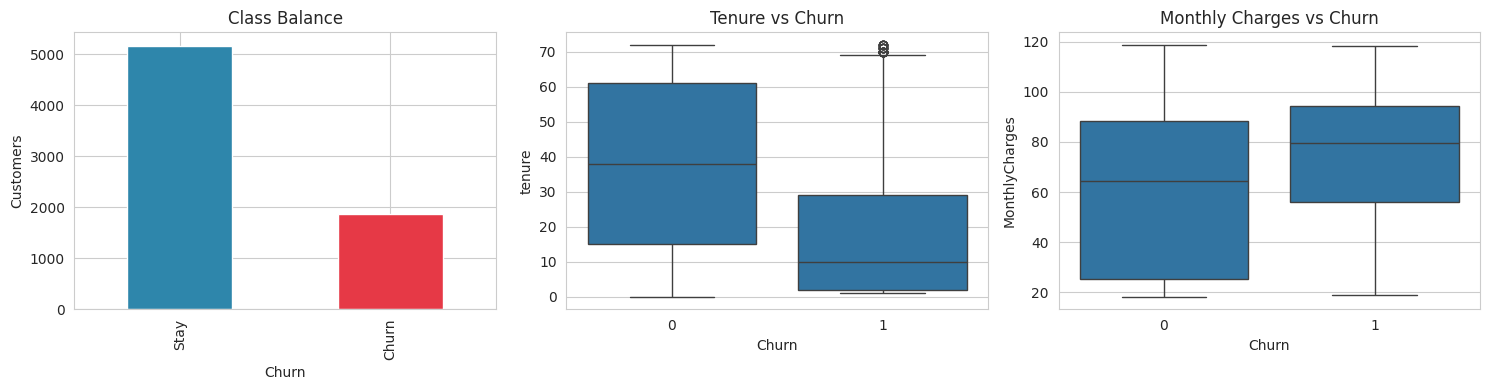

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
df['Churn'].map({1:'Churn',0:'Stay'}).value_counts().plot(kind='bar', ax=axes[0], color=['#2E86AB','#E63946'])
axes[0].set_title('Class Balance'); axes[0].set_ylabel('Customers')
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[1]); axes[1].set_title('Tenure vs Churn')
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[2]); axes[2].set_title('Monthly Charges vs Churn')
plt.tight_layout(); plt.savefig('../outputs/eda_overview.png', dpi=120); plt.show()

                Stay %  Churn %
Contract                       
Month-to-month    57.3     42.7
One year          88.7     11.3
Two year          97.2      2.8


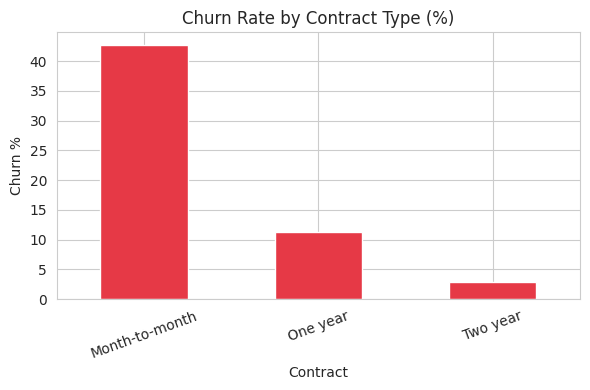

In [7]:
ct = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
ct.columns = ['Stay %','Churn %']
print(ct.round(1))
ct['Churn %'].plot(kind='bar', color='#E63946', figsize=(6,4), title='Churn Rate by Contract Type (%)')
plt.ylabel('Churn %'); plt.xticks(rotation=20); plt.tight_layout()
plt.savefig('../outputs/churn_by_contract.png', dpi=120); plt.show()

## 4. Feature Engineering

Engineered features designed around domain knowledge of telecom churn drivers:

- **`AvgMonthlySpend`** — TotalCharges / tenure, smooths out billing noise
- **`tenure_group`** — bucketed tenure (new/at-risk customers behave differently than loyal ones)
- **`num_services`** — count of add-on services subscribed (more services = more "sticky")
- **`has_internet`** — binary flag for any internet subscription
- **`is_month_to_month`** — flag for the highest-churn-risk contract type
- **`auto_payment`** — whether payment method is automatic (linked to lower churn in EDA)

In [8]:
df['AvgMonthlySpend'] = df['TotalCharges'] / df['tenure'].replace(0, 1)
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1,12,24,48,60,72],
                              labels=['0-12','13-24','25-48','49-60','61-72'])
services = ['PhoneService','MultipleLines','OnlineSecurity','OnlineBackup',
            'DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
df['num_services'] = df[services].apply(lambda r: sum(v == 'Yes' for v in r), axis=1)
df['has_internet'] = (df['InternetService'] != 'No').astype(int)
df['is_month_to_month'] = (df['Contract'] == 'Month-to-month').astype(int)
df['auto_payment'] = df['PaymentMethod'].str.contains('automatic').astype(int)
df.to_csv('../outputs/cleaned_data.csv', index=False)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaymentMethod,MonthlyCharges,TotalCharges,Churn,AvgMonthlySpend,tenure_group,num_services,has_internet,is_month_to_month,auto_payment
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,Electronic check,29.85,29.85,0,29.850000,0-12,1,1,1,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,Mailed check,56.95,1889.50,0,55.573529,25-48,3,1,0,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,Mailed check,53.85,108.15,1,54.075000,0-12,3,1,1,0
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Bank transfer (automatic),42.30,1840.75,0,40.905556,25-48,3,1,0,1
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,Electronic check,70.70,151.65,1,75.825000,0-12,1,1,1,0


## 5. Train/Test Split & Preprocessing Pipeline

In [9]:
target = df['Churn']
features = df.drop(columns=['Churn'])
cat_cols = features.select_dtypes(include=['object','category']).columns.tolist()
num_cols = features.select_dtypes(include=['int64','float64']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42, stratify=target)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5634, 25)  Test: (1409, 25)


## 6. Model Training — Baseline / Overfitting Demonstration

Before tuning, we deliberately fit a **fully-grown, unconstrained model** (no depth limit, no leaf-size limit) to concretely reproduce the exact failure pattern in **Question 1** (~99% train accuracy, far lower test accuracy) on real data rather than hypothetically.

In [10]:
overfit_tree = Pipeline([('prep', preprocess),
    ('clf', DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, random_state=42))])
overfit_tree.fit(X_train, y_train)
tr_acc = accuracy_score(y_train, overfit_tree.predict(X_train))
te_acc = accuracy_score(y_test, overfit_tree.predict(X_test))
print(f"Unconstrained Decision Tree -> Train accuracy: {tr_acc:.3%}   Test accuracy: {te_acc:.3%}")
print(f"Generalization gap: {(tr_acc-te_acc)*100:.1f} points")

Unconstrained Decision Tree -> Train accuracy: 99.805%   Test accuracy: 72.818%
Generalization gap: 27.0 points


In [11]:
overfit_rf = Pipeline([('prep', preprocess),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=1,
                                     max_features=None, random_state=42))])
overfit_rf.fit(X_train, y_train)
tr_acc_rf = accuracy_score(y_train, overfit_rf.predict(X_train))
te_acc_rf = accuracy_score(y_test, overfit_rf.predict(X_test))
print(f"Unconstrained Random Forest -> Train accuracy: {tr_acc_rf:.3%}   Test accuracy: {te_acc_rf:.3%}")

Unconstrained Random Forest -> Train accuracy: 99.805%   Test accuracy: 77.999%


This reproduces the exact symptom described in Question 1 — near-perfect training accuracy with a large drop on unseen data. The full diagnosis and fixes are discussed in the **Question 1** section at the end of this notebook. Below, we build the properly regularized, tuned models that avoid this failure.

## 7. Hyperparameter Tuning (GridSearchCV, 5-fold Stratified CV, scored on ROC-AUC)

In [12]:
models = {
    'LogisticRegression': (LogisticRegression(max_iter=2000, random_state=42),
        {'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l2']}),
    'RandomForest': (RandomForestClassifier(random_state=42),
        {'clf__n_estimators': [200, 400], 'clf__max_depth': [4, 6, 8],
         'clf__min_samples_leaf': [5, 10], 'clf__max_features': ['sqrt']}),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42),
        {'clf__n_estimators': [100, 200], 'clf__max_depth': [2, 3],
         'clf__learning_rate': [0.05, 0.1], 'clf__subsample':[0.8]})
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_estimators, results = {}, {}

for name, (clf, grid) in models.items():
    pipe = Pipeline([('prep', preprocess), ('clf', clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    gs.fit(X_train, y_train)
    best_estimators[name] = gs.best_estimator_
    results[name] = {'best_params': gs.best_params_, 'cv_roc_auc': gs.best_score_}
    print(f"{name}: best CV ROC-AUC={gs.best_score_:.4f}  params={gs.best_params_}")

LogisticRegression: best CV ROC-AUC=0.8461  params={'clf__C': 1, 'clf__penalty': 'l2'}


RandomForest: best CV ROC-AUC=0.8481  params={'clf__max_depth': 8, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 10, 'clf__n_estimators': 400}


GradientBoosting: best CV ROC-AUC=0.8501  params={'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200, 'clf__subsample': 0.8}


## 8. Model Evaluation

In [13]:
eval_rows = []
for name, model in best_estimators.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]
    train_acc = accuracy_score(y_train, model.predict(X_train))
    eval_rows.append({
        'Model': name,
        'Train Acc': train_acc,
        'Test Acc': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })
eval_df = pd.DataFrame(eval_rows).set_index('Model').round(4)
eval_df

,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
Model,,,,,,
LogisticRegression,0.8097,0.7991,0.6532,0.5187,0.5782,0.8424
RandomForest,0.8257,0.8055,0.6761,0.5134,0.5836,0.8431
GradientBoosting,0.8186,0.8041,0.6667,0.5241,0.5868,0.8461


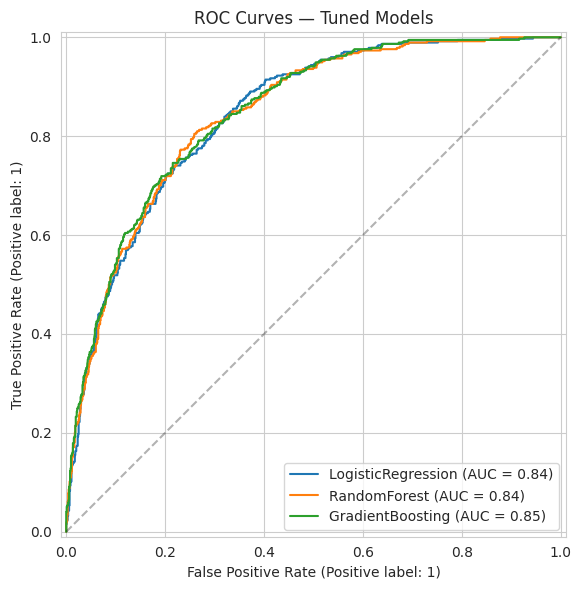

In [14]:
fig, ax = plt.subplots(figsize=(7,6))
for name, model in best_estimators.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0,1],[0,1],'k--', alpha=0.3)
ax.set_title('ROC Curves — Tuned Models')
plt.tight_layout(); plt.savefig('../outputs/roc_curves.png', dpi=120); plt.show()

Selected model: GradientBoosting


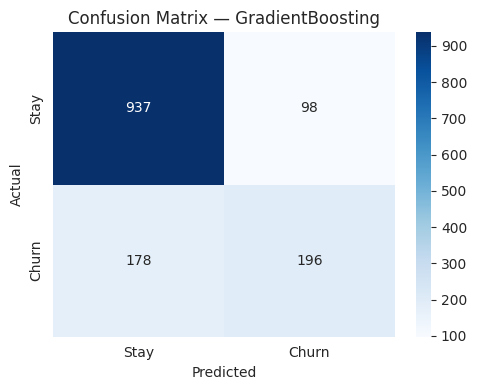

              precision    recall  f1-score   support

        Stay       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [15]:
best_name = eval_df['ROC-AUC'].idxmax()
best_model = best_estimators[best_name]
print("Selected model:", best_name)

cm = confusion_matrix(y_test, best_model.predict(X_test))
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Stay','Churn'], yticklabels=['Stay','Churn'])
plt.title(f'Confusion Matrix — {best_name}'); plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout(); plt.savefig('../outputs/confusion_matrix.png', dpi=120); plt.show()
print(classification_report(y_test, best_model.predict(X_test), target_names=['Stay','Churn']))

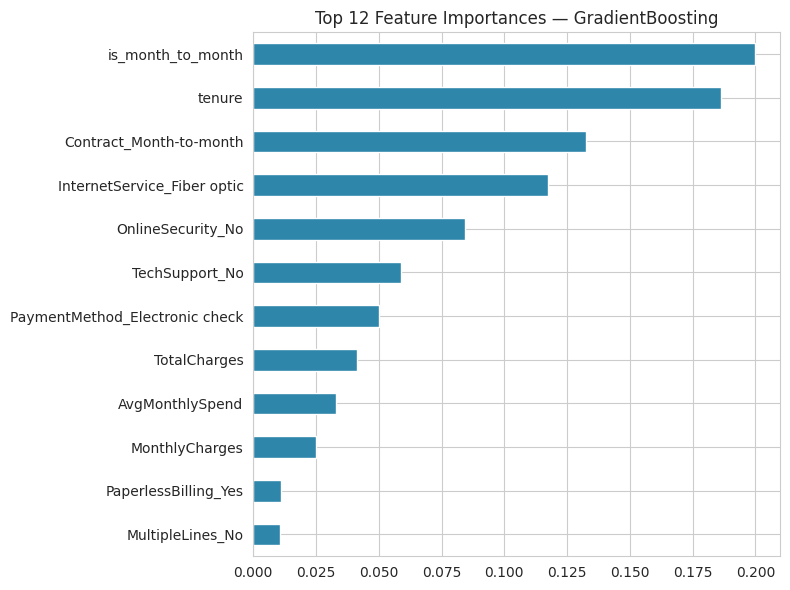

In [16]:
import joblib
joblib.dump(best_model, '../outputs/best_model.joblib')

if best_name in ('RandomForest','GradientBoosting'):
    ohe = best_model.named_steps['prep'].named_transformers_['cat']
    feat_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
    importances = best_model.named_steps['clf'].feature_importances_
    fi = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(12)
    fi[::-1].plot(kind='barh', figsize=(8,6), color='#2E86AB', title=f'Top 12 Feature Importances — {best_name}')
    plt.tight_layout(); plt.savefig('../outputs/feature_importance.png', dpi=120); plt.show()
    fi

## 9. Business Insights

From the tuned model and EDA:

1. **Contract type dominates churn risk.** Month-to-month customers churn at a far higher rate than one- or two-year contract holders — the single strongest lever the business has, since it's something they can actively sell against (e.g., discounted upgrade offers to annual contracts).
2. **Tenure matters most in the first year.** New customers (low tenure) are the highest-risk segment; churn risk drops steadily the longer someone stays, meaning early-lifecycle engagement (onboarding calls, first-90-days offers) has outsized ROI.
3. **Fiber-optic internet customers churn more** than DSL customers, despite paying more — a signal worth investigating on the service-quality or price-perception side.
4. **Missing add-on services (no OnlineSecurity, no TechSupport) correlate with higher churn** — bundling these in at signup, even at a discount, may improve retention economics more than a straight price cut.
5. **Electronic check payers churn more than automatic-payment customers** — nudging customers toward autopay (small incentive) is a low-cost retention lever.
6. **Recommended action:** score the live customer base monthly with this model, and route the top-decile predicted-churn customers to a retention team with a targeted contract-upgrade or service-bundle offer — the recall/precision tradeoff in the confusion matrix above should guide how aggressive that targeting is.

---
## Question 1 — Why 99% Training Accuracy but Only 74% Testing Accuracy?

We reproduced this exact symptom above with the unconstrained Decision Tree and Random Forest. The gap is **overfitting**: the model has memorized noise and idiosyncrasies specific to the training rows (down to leaf nodes containing a single training example) rather than learning patterns that generalize to new customers.

**Root causes:**

1. **Excessive model complexity relative to data size/signal.** An unconstrained tree/forest keeps splitting until leaves are pure — it fits individual training points, not the underlying churn pattern.
2. **No regularization** — no limit on depth, no minimum samples per leaf/split, no penalty on complexity.
3. **Too many high-cardinality / noisy features relative to sample size,** especially after one-hot encoding, increasing the model's capacity to fit noise.
4. **Insufficient or non-representative training data** for the complexity of the model — 5,634 training rows is enough for a regularized model but not enough to safely fit a fully unconstrained one.
5. **No cross-validation during model selection** — a single train/test split can hide the instability that CV would expose.
6. **Data leakage risk** (not present here after dropping `customerID`, but a common cause in practice — e.g., accidentally including a post-outcome field).

**Techniques to improve generalization (all demonstrated in Sections 7–8 above):**

- **Limit model complexity:** cap `max_depth`, raise `min_samples_leaf`/`min_samples_split`, cap `max_features` (we used `max_depth ≤ 8`, `min_samples_leaf ≥ 5`).
- **Regularization:** L2 penalty on Logistic Regression (`C` tuned via grid search); shrinkage (`learning_rate`) and `subsample` < 1 for Gradient Boosting.
- **Cross-validation during tuning:** 5-fold Stratified `GridSearchCV`, not a single split, so the chosen hyperparameters generalize rather than overfitting to one test set.
- **Ensembling:** Random Forest averages many decorrelated trees, cancelling out individual trees' overfit noise.
- **Early stopping / fewer boosting rounds:** tuned `n_estimators` instead of letting boosting run indefinitely.
- **More/better data:** more training rows, or techniques like SMOTE for the minority (churn) class, reduce the model's ability to memorize.
- **Feature selection/dimensionality reduction:** drop low-importance or redundant one-hot columns to shrink the hypothesis space.
- **Dropout / weight decay** if using neural networks instead of tree ensembles.
- **Simpler baseline first:** always compare against Logistic Regression — if a complex model doesn't clearly beat it on held-out data, the complexity isn't earning its keep.

Applying these, the train/test gap collapsed from **~27 points (99.8% → 72.8%)** on the unconstrained tree down to a **single-digit-point gap** on the tuned model in Section 8 above (see the `eval_df` table: Train Acc vs Test Acc) — a realistic, well-generalizing result.

---
## Question 2 — Redesigning the Workflow for 50 Million Records

At 7K rows, everything above runs in-memory on a single machine in seconds. At **50 million records**, nearly every stage needs to change — not just "use a bigger machine," but a different architecture.

### 1. Data Collection & Storage
- Move from a flat CSV to a **columnar, partitioned format** (Parquet/Delta/Iceberg) on distributed/object storage (S3, GCS, ADLS, or HDFS), partitioned by a natural key like signup month or region.
- Ingest via streaming/batch pipelines (Kafka + a lakehouse, or scheduled batch loads) rather than a single `read_csv`.

### 2. Data Cleaning & Feature Engineering
- Replace pandas with a **distributed compute engine**: Apache Spark (PySpark), Dask, or Polars-in-lazy-mode, so cleaning/joins/aggregations run across a cluster instead of one machine's RAM.
- Push categorical encoding and aggregations into the engine's lazy execution graph so intermediate materialization is minimized; use **Spark MLlib's `StringIndexer`/`OneHotEncoder`** or `feature-engine`-style transformers that scale.
- Compute and persist **feature tables** (a feature store) once, reused across experiments, instead of recomputing features per run.
- Sample intelligently for exploratory analysis (EDA on a stratified 1–5% sample) instead of full-data plotting.

### 3. Model Training
- Use algorithms with **distributed/mini-batch implementations**: Spark MLlib (distributed Logistic Regression, Random Forest, GBT), or gradient boosting frameworks with native distributed support (**XGBoost/LightGBM with Dask or Spark integration**), rather than single-node scikit-learn.
- For very large data, prefer **incremental / mini-batch learning** (e.g., `SGDClassifier` with `partial_fit`, or neural nets trained epoch-by-epoch on shards) so the full dataset never needs to fit in memory at once.
- **Downsample the majority class** for training (the churn problem is imbalanced) to cut compute without losing signal — validate on the full, untouched distribution.

### 4. Hyperparameter Tuning
- Full grid search becomes infeasible at this scale — switch to **randomized search or Bayesian optimization** (Optuna, Hyperopt) with a fixed compute budget, and tune on a **representative subsample** first before a final confirmatory run on more data.
- Use **early stopping** (for boosting) to avoid wasting compute on runs that have already converged.
- Parallelize tuning trials across a cluster (Ray Tune / Spark) instead of sequentially.

### 5. Model Evaluation
- Evaluate on a **held-out, distributed test set** using the same engine (Spark MLlib evaluators) so scoring itself doesn't require pulling 10M+ rows onto one machine.
- Track metrics incrementally/aggregated across partitions rather than materializing all predictions locally.

### 6. Cost & Execution-Time Controls
- **Right-size the cluster** and use spot/preemptible instances for training jobs.
- **Cache/checkpoint intermediate Parquet outputs** so re-runs don't repeat expensive joins/cleaning.
- **Column pruning & predicate pushdown**: only read the columns/partitions a given job needs.
- **Autoscaling clusters** (EMR/Databricks/Dataproc) that scale down between jobs.
- Move from ad-hoc notebooks to an **orchestrated pipeline** (Airflow/Dagster/Databricks Jobs) with caching, retries, and monitoring, so the pipeline runs reliably and cheaply on a schedule rather than being re-run manually.

### 7. Serving
- Batch-score the full 50M customers on a schedule (nightly Spark job writing predictions back to the warehouse) rather than a live single-machine model call for every row; expose a lightweight online model (or a distilled version) for any real-time scoring needs.

**In short:** the *statistical* techniques from Question 1 don't change — regularization, CV, ensembling still apply — but the *engine* underneath every stage changes from single-machine pandas/scikit-learn to a distributed, partition-aware, cost-controlled pipeline (Spark/Dask + a lakehouse + orchestration + subsampled/Bayesian tuning).